<a href="https://colab.research.google.com/github/sashawrk4-pylyp/My-Python-Data-Analysis/blob/main/Sample_Size_Estimation_for_A_B_Testing.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [26]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.stats.api as sms
from statsmodels.stats.proportion import proportion_effectsize

In [27]:
# Розрахунок розміру вибірки з 3%
baseline_conversion = 0.10

expected_lift = 0.03 * baseline_conversion
variant_conversion = baseline_conversion + expected_lift

effect_size = proportion_effectsize(baseline_conversion, variant_conversion)

alpha = 0.05  # Significance level (5%)
power = 0.80  # Test power (80%)

sample_size = sms.NormalIndPower().solve_power(effect_size=effect_size, power=power, alpha=alpha, ratio=1)
print(f"Required sample size for each group: {int(np.ceil(sample_size))}")

Required sample size for each group: 159059


За базової конверсії 10% та очікуваного відносного зростання на 3% (до 10,3%) для проведення A/B-тесту з рівнем значущості 5% і потужністю 80% необхідно 159 059 користувачів у кожній групі. Отже, загальна вибірка має становити 318 118 користувачів.

In [28]:
# Розрахунок розміру вибірки з 1%
baseline_conversion = 0.10

expected_lift = 0.03 * baseline_conversion
variant_conversion = baseline_conversion + expected_lift

effect_size = proportion_effectsize(baseline_conversion, variant_conversion)

alpha = 0.01  # Significance level (1%)
power = 0.80  # Test power (80%)

sample_size = sms.NormalIndPower().solve_power(effect_size=effect_size, power=power, alpha=alpha, ratio=1)
print(f"Required sample size for each group: {int(np.ceil(sample_size))}")

Required sample size for each group: 236676


За базової конверсії 10% та очікуваного зростання на 3% (до 10,3%), при зниженні рівня значущості до 1% і потужності тесту 80% необхідно 236 676 користувачів у кожній групі. Загальний розмір вибірки становить 473 352 користувачі. Це більше, ніж у попередньому сценарії з рівнем значущості 5%, оскільки суворіші вимоги потребують більшої вибірки.

In [29]:
# 1% різниця в конверсії
baseline_conversion = 0.10

# Expected effect (1% relative difference in conversion)
expected_lift = 0.01 * baseline_conversion
variant_conversion = baseline_conversion + expected_lift

effect_size = proportion_effectsize(baseline_conversion, variant_conversion)

alpha = 0.05  # Significance level (5%)
power = 0.80  # Test power (80%)

sample_size = sms.NormalIndPower().solve_power(effect_size=effect_size, power=power, alpha=alpha, ratio=1)
print(f"Required sample size for each group: {int(np.ceil(sample_size))}")

Required sample size for each group: 1419062


За базової конверсії 10% та очікуваного відносного зростання на 1% (до 10,1%), при рівні значущості 5% і потужності тесту 80% необхідно 1 419 062 користувачів у кожній групі. Загальний розмір вибірки становить 2 838 124 користувачі. Значне збільшення вибірки порівняно з попередніми сценаріями пояснюється тим, що меншу різницю в конверсії складніше виявити статистично.

In [30]:
# Порівняння сценаріїв A/B-тесту
scenarios = [
    ("3% lift, alpha 5%", 0.10, 0.03, 0.05),
    ("3% lift, alpha 1%", 0.10, 0.03, 0.01),
    ("1% lift, alpha 5%", 0.10, 0.01, 0.05)]

results = []
for name, baseline, lift, alpha in scenarios:
    variant = baseline + baseline * lift
    effect = proportion_effectsize(baseline, variant)

    sample = sms.NormalIndPower().solve_power(
        effect_size=effect,
        power=0.80,
        alpha=alpha,
        ratio=1)

    results.append({
        "Scenario": name,
        "Baseline conversion": baseline,
        "Variant conversion": variant,
        "Alpha": alpha,
        "Sample per group": int(np.ceil(sample)),
        "Total sample": int(np.ceil(sample)) * 2})

results_df = pd.DataFrame(results)
results_df

,Scenario,Baseline conversion,Variant conversion,Alpha,Sample per group,Total sample
0,"3% lift, alpha 5%",0.1,0.103,0.05,159059,318118
1,"3% lift, alpha 1%",0.1,0.103,0.01,236676,473352
2,"1% lift, alpha 5%",0.1,0.101,0.05,1419062,2838124


Таблиця порівнює три сценарії розрахунку розміру вибірки для A/B-тесту. Найменша вибірка потрібна для сценарію з очікуваним зростанням конверсії на 3% і рівнем значущості 5% — 159 059 користувачів на групу. Найбільша — для виявлення зростання на 1% — 1 419 062 користувачів на групу. Отже, що менший очікуваний ефект і суворіший рівень значущості, то більше даних потрібно для проведення тесту.

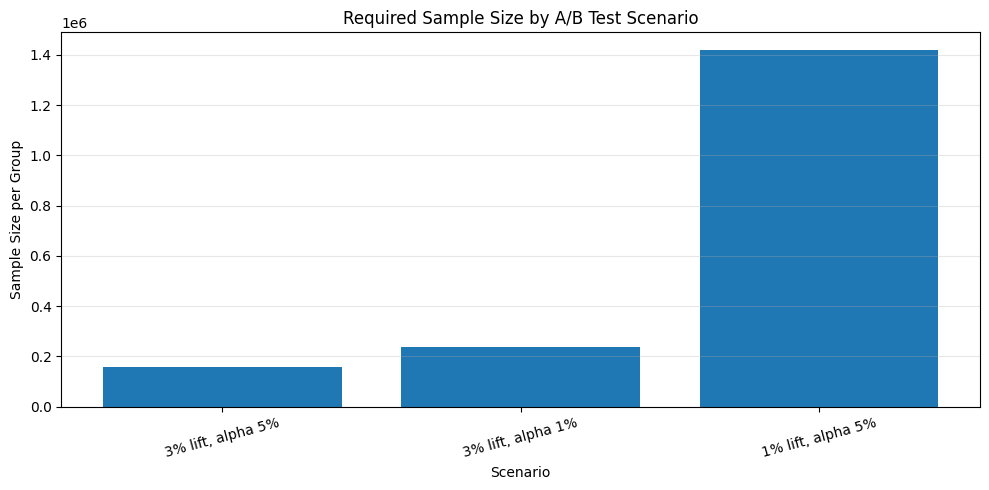

In [31]:
# Порівняння необхідного розміру вибірки
plt.figure(figsize=(10, 5))

plt.bar(results_df["Scenario"], results_df["Sample per group"])
plt.title("Required Sample Size by A/B Test Scenario")
plt.xlabel("Scenario")
plt.ylabel("Sample Size per Group")
plt.xticks(rotation=15)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

На графіку порівнюється необхідний розмір вибірки для трьох сценаріїв A/B-тесту. Найбільша вибірка потрібна для виявлення відносного зростання конверсії на 1%, тоді як найменша — для зростання на 3% при рівні значущості 5%. Це наочно демонструє, як очікуваний ефект і рівень значущості впливають на кількість необхідних учасників.

In [32]:
# Вплив потужності тесту на розмір вибірки
power_levels = [0.70, 0.80, 0.90, 0.95]
sample_sizes = []
baseline_conversion = 0.10
variant_conversion = 0.103
effect_size = proportion_effectsize(baseline_conversion, variant_conversion)
for power_level in power_levels:
    sample = sms.NormalIndPower().solve_power(
        effect_size=effect_size,
        power=power_level,
        alpha=0.05,
        ratio=1)

    sample_sizes.append(int(np.ceil(sample)))
power_df = pd.DataFrame({
    "Power": power_levels,
    "Sample Size per Group": sample_sizes})

power_df

,Power,Sample Size per Group
0,0.70,125077
1,0.80,159059
2,0.90,212935
3,0.95,263340


Таблиця демонструє, як зміна статистичної потужності впливає на необхідний розмір вибірки. При збільшенні потужності з 70% до 95% кількість користувачів у кожній групі зростає зі 125 077 до 263 340. Це означає, що для підвищення ймовірності виявлення реального ефекту A/B-тесту необхідно залучати більше учасників.